O que é o IDHM
Links importantes
https://www.undp.org/pt/brazil/o-que-%C3%A9-o-idhm
Base de dados Ipea
https://www.ipea.gov.br/ipeageo/arquivos/bases/IDH_2010.xls

O Índice de Desenvolvimento Humano Municipal (IDHM) é uma medida composta de indicadores de três dimensões do desenvolvimento humano: longevidade, educação e renda. O índice varia de 0 a 1. Quanto mais próximo de 1, maior o desenvolvimento humano.

O IDHM brasileiro segue as mesmas três dimensões do IDH Global - longevidade, educação e renda, mas vai além: adequa a metodologia global ao contexto brasileiro e à disponibilidade de indicadores nacionais. Embora meçam os mesmos fenômenos, os indicadores levados em conta no IDHM são mais adequados para avaliar o desenvolvimento dos municípios brasileiros. Assim, o IDHM - incluindo seus três componentes, IDHM Longevidade, IDHM Educação e IDHM Renda - conta um pouco da história dos municípios em três importantes dimensões do desenvolvimento humano durantes duas décadas da história brasileira.

Pergunta Norteadora: "Quais são os Estados que possuem um bom IDH para que possamos entregar bons produtos."

In [1]:
%pip install xlrd
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install seaborn
%pip install plotly
%pip install --upgrade nbformat ipython

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


Pergunta Norteadora: "Quais são os Estados que possuem um bom IDH para que possamos entregar bons produtos".

In [2]:
import pandas as pd
import numpy as np

# Libs - Gráficas
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#Avisos
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_excel('data/IDH_2010.xls')

In [4]:
#Leitura da base de dados
idhm = pd.read_excel("data/IDH_2010.xls")

In [5]:
#Leitura dos primeiros regitros
idhm.head()

,ANO,Código da Unidade da Federação,Nome da Unidade da Federação,Código do Município,Município,Esperança de vida ao nascer,Taxa de fecundidade total,Mortalidade infantil,Mortalidade até 5 anos de idade,Razão de dependência,...,População de 15 a 17 anos.1,População de 18 anos ou mais.1,População total em domicílios particulares permanentes,"População total em domicílios particulares permanentes, exceto com renda nula",Subíndice de escolaridade - IDHM Educação,Subíndice de frequência escolar - IDHM Educação,IDHM,IDHM Educação,IDHM Longevidade,IDHM Renda
0,2010,11,Rondônia,110001,ALTA FLORESTA D'OESTE,70.75,2.24,23.8,25.49,47.37,...,1602,16431,24097,22429,0.368,0.629,0.641,0.526,0.763,0.657
1,2010,11,Rondônia,110002,ARIQUEMES,73.36,1.91,19.2,20.53,46.68,...,5256,60213,89766,88730,0.514,0.648,0.702,0.600,0.806,0.716
2,2010,11,Rondônia,110003,CABIXI,70.39,2.15,24.8,26.58,48.12,...,381,4306,6303,6156,0.357,0.700,0.650,0.559,0.757,0.650
3,2010,11,Rondônia,110004,CACOAL,74.27,1.90,14.3,15.38,43.79,...,4547,54356,78141,76876,0.488,0.698,0.718,0.620,0.821,0.727
4,2010,11,Rondônia,110005,CEREJEIRAS,72.94,2.12,18.1,19.42,45.67,...,1033,11786,16942,16815,0.430,0.712,0.692,0.602,0.799,0.688


Tamanho da base de dados

In [6]:
print(f'Tamanho do nosso dataset (Linhas, Colunas): {idhm.shape}')

Tamanho do nosso dataset (Linhas, Colunas): (5564, 237)


Verificar os tipos dos dados

In [7]:
idhm.dtypes

ANO                                                  int64
Código da Unidade da Federação                       int64
Nome da Unidade da Federação                           str
Código do Município                                  int64
Município                                              str
                                                    ...   
Subíndice de frequência escolar - IDHM Educação    float64
IDHM                                               float64
IDHM Educação                                      float64
IDHM Longevidade                                   float64
IDHM Renda                                         float64
Length: 237, dtype: object

Valores nulos

In [8]:
idhm.isnull().sum()

ANO                                                0
Código da Unidade da Federação                     0
Nome da Unidade da Federação                       0
Código do Município                                0
Município                                          0
                                                  ..
Subíndice de frequência escolar - IDHM Educação    0
IDHM                                               0
IDHM Educação                                      0
IDHM Longevidade                                   0
IDHM Renda                                         0
Length: 237, dtype: int64

In [9]:
print(f'Quantidade de dados nulos no nosso dataframe: {idhm.isnull().sum().sum()}')

Quantidade de dados nulos no nosso dataframe: 0


In [10]:
idhm.columns

Index(['ANO', 'Código da Unidade da Federação', 'Nome da Unidade da Federação',
       'Código do Município', 'Município', 'Esperança de vida ao nascer',
       'Taxa de fecundidade total', 'Mortalidade infantil',
       'Mortalidade até 5 anos de idade', 'Razão de dependência',
       ...
       'População de 15 a 17 anos.1', 'População de 18 anos ou mais.1',
       'População total em domicílios particulares permanentes',
       'População total em domicílios particulares permanentes, exceto com renda nula',
       'Subíndice de escolaridade - IDHM Educação',
       'Subíndice de frequência escolar - IDHM Educação', 'IDHM',
       'IDHM Educação', 'IDHM Longevidade', 'IDHM Renda'],
      dtype='str', length=237)

In [11]:
df_idhm = idhm [['Nome da Unidade da Federação', 'Município', 'IDHM', 'IDHM Educação', 'IDHM Longevidade', 'IDHM Renda']]

In [12]:
df_idhm.head()

,Nome da Unidade da Federação,Município,IDHM,IDHM Educação,IDHM Longevidade,IDHM Renda
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688


In [13]:
df_idhm.columns = ['uf', 'municipio', 'idhm', 'idhm_educacao', 'idhm_longevidade', 'idhm_renda']

In [14]:
df_idhm.head()

,uf,municipio,idhm,idhm_educacao,idhm_longevidade,idhm_renda
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688


In [15]:
df_idhm.info()

<class 'pandas.DataFrame'>
RangeIndex: 5564 entries, 0 to 5563
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   uf                5564 non-null   str    
 1   municipio         5564 non-null   str    
 2   idhm              5564 non-null   float64
 3   idhm_educacao     5564 non-null   float64
 4   idhm_longevidade  5564 non-null   float64
 5   idhm_renda        5564 non-null   float64
dtypes: float64(4), str(2)
memory usage: 260.9 KB


Valores Únicos

In [16]:
df_idhm.nunique()

uf                    27
municipio           5329
idhm                 349
idhm_educacao        466
idhm_longevidade     220
idhm_renda           390
dtype: int64

Estatística Descritiva

In [17]:
df_idhm.describe().round(2)

,idhm,idhm_educacao,idhm_longevidade,idhm_renda
count,5564.00,5564.00,5564.00,5564.00
mean,0.66,0.56,0.80,0.64
std,0.07,0.09,0.04,0.08
min,0.42,0.21,0.67,0.40
25%,0.60,0.49,0.77,0.57
50%,0.66,0.56,0.81,0.65
75%,0.72,0.63,0.84,0.71
max,0.86,0.82,0.89,0.89


Classificação IDHM <br/>
0 - 0,499 Baixo Desenvolvimento Humano <br/>
0,5 - 0,799 Médio Desenvolvimento Humano <br/>
0,8 - 1 Alto Desenvolvimento Humano

In [18]:
df_idhm['idhm']

0       0.641
1       0.702
2       0.650
3       0.718
4       0.692
        ...  
5559    0.712
5560    0.684
5561    0.647
5562    0.634
5563    0.824
Name: idhm, Length: 5564, dtype: float64

In [19]:
#Fução Classificação IDHM
def idhm_class(df):
  if df['idhm'] <= 0.499:
    return 'Baixo Desenvolvimento Humano'
  elif df['idhm'] >= 0.5 and df['idhm'] <= 0.799:
    return 'Médio Desenvolvimento Humano'
  else:
    return 'Alto Desenvolvimento Humano'

In [47]:
df_idhm['classe'] = df_idhm.apply(idhm_class, axis=1)
df_idhm

,uf,municipio,idhm,idhm_educacao,idhm_longevidade,idhm_renda,classe
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657,Médio Desenvolvimento Humano
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716,Médio Desenvolvimento Humano
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650,Médio Desenvolvimento Humano
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727,Médio Desenvolvimento Humano
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688,Médio Desenvolvimento Humano
...,...,...,...,...,...,...,...
5559,Goiás,VIANÓPOLIS,0.712,0.622,0.818,0.710,Médio Desenvolvimento Humano
5560,Goiás,VICENTINÓPOLIS,0.684,0.562,0.804,0.707,Médio Desenvolvimento Humano
5561,Goiás,VILA BOA,0.647,0.534,0.818,0.619,Médio Desenvolvimento Humano
5562,Goiás,VILA PROPÍCIO,0.634,0.505,0.802,0.629,Médio Desenvolvimento Humano


In [21]:
df_idhm.head()

,uf,municipio,idhm,idhm_educacao,idhm_longevidade,idhm_renda,classe
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657,Médio Desenvolvimento Humano
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716,Médio Desenvolvimento Humano
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650,Médio Desenvolvimento Humano
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727,Médio Desenvolvimento Humano
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688,Médio Desenvolvimento Humano


In [22]:
df_idhm['classe'].value_counts()

classe
Médio Desenvolvimento Humano    5488
Alto Desenvolvimento Humano       44
Baixo Desenvolvimento Humano      32
Name: count, dtype: int64

Pairplot

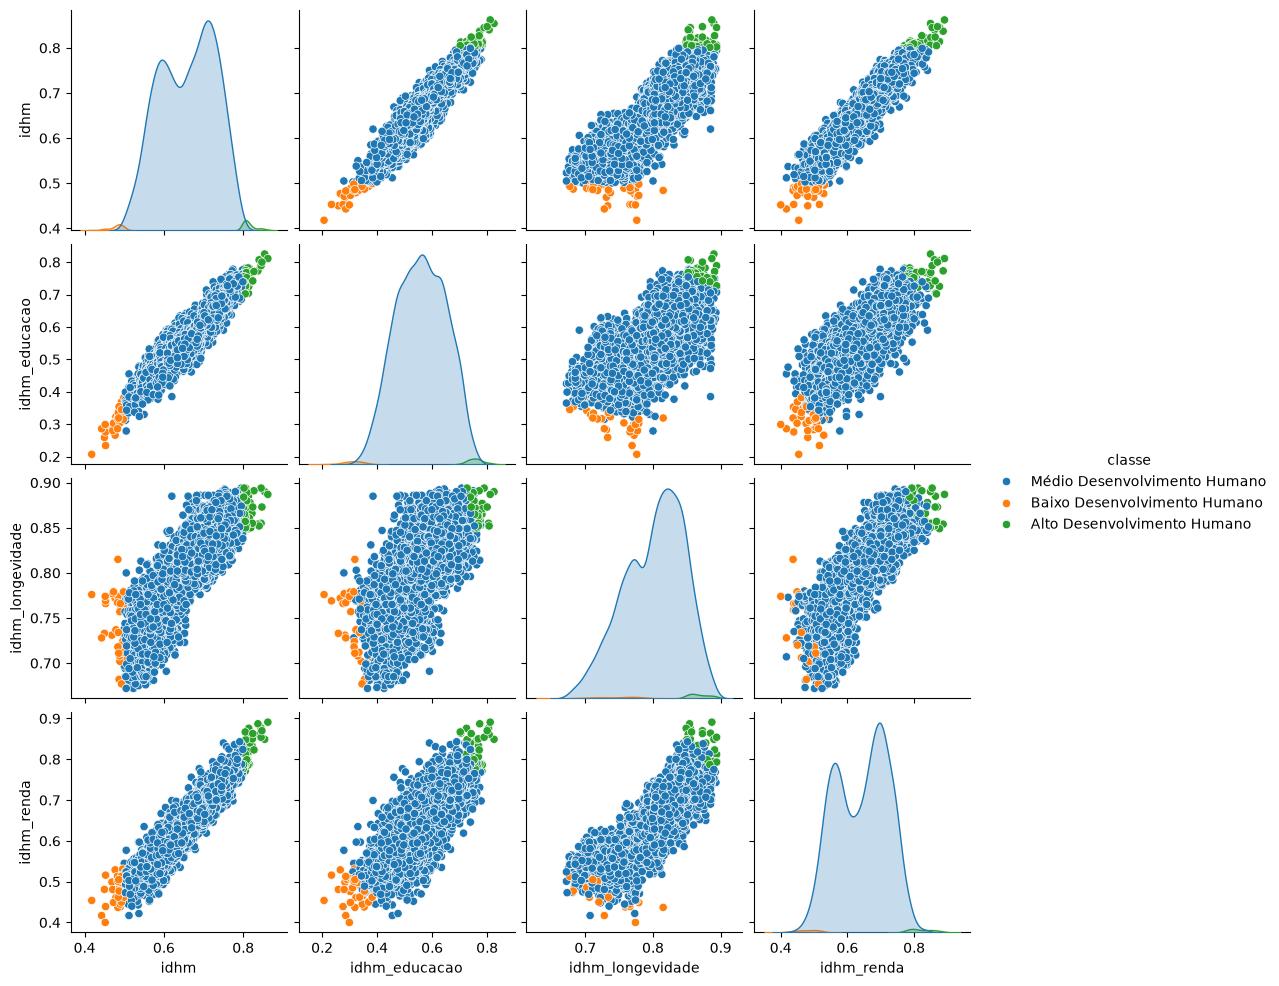

In [23]:
sns.pairplot(df_idhm, hue='classe')

Interessante observar a relação entre a renda e a escolaridade. Parece ter relação.

## Análise por estado

In [55]:
df_idhm_estado = pd.DataFrame(df_idhm.groupby('uf')['idhm'].mean().round(2)).reset_index()
df_idhm_estado

,uf,idhm
0,Acre,0.59
1,Alagoas,0.56
2,Amapá,0.64
3,Amazonas,0.57
4,Bahia,0.59
5,Ceará,0.62
6,Distrito Federal,0.82
7,Espírito Santo,0.69
8,Goiás,0.69
9,Maranhão,0.58


In [56]:
df_idhm_estado['classe'] = df_idhm_estado.apply(idhm_class, axis=1)
df_idhm_estado

,uf,idhm,classe
0,Acre,0.59,Médio Desenvolvimento Humano
1,Alagoas,0.56,Médio Desenvolvimento Humano
2,Amapá,0.64,Médio Desenvolvimento Humano
3,Amazonas,0.57,Médio Desenvolvimento Humano
4,Bahia,0.59,Médio Desenvolvimento Humano
5,Ceará,0.62,Médio Desenvolvimento Humano
6,Distrito Federal,0.82,Alto Desenvolvimento Humano
7,Espírito Santo,0.69,Médio Desenvolvimento Humano
8,Goiás,0.69,Médio Desenvolvimento Humano
9,Maranhão,0.58,Médio Desenvolvimento Humano


In [26]:
df_idhm_estado['classe'].value_counts()

classe
Médio Desenvolvimento Humano    26
Alto Desenvolvimento Humano      1
Name: count, dtype: int64

In [27]:
df_idhm_estado.info()

<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   uf      27 non-null     str    
 1   idhm    27 non-null     float64
 2   classe  27 non-null     str    
dtypes: float64(1), str(2)
memory usage: 780.0 bytes


Estatística Descritiva dos Estados quanto ao IDHM Geral

In [28]:
df_idhm_estado.describe().round(2)

,idhm
count,27.00
mean,0.64
std,0.06
min,0.56
25%,0.59
50%,0.64
75%,0.69
max,0.82


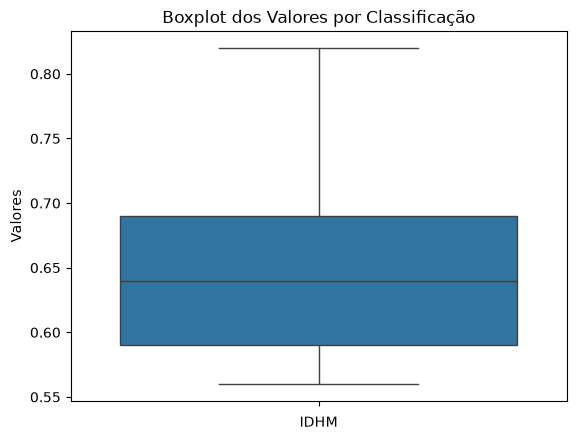

In [29]:
# Usando o seaborn para gráfico de boxplot
sns.boxplot(y = df_idhm_estado['idhm'], data=df_idhm_estado)

# Adicionar título e rótulos para eixos.
plt.title('Boxplot dos Valores por Classificação')
plt.xlabel('IDHM')
plt.ylabel('Valores')
plt.show()

Criar um gráfico de barra

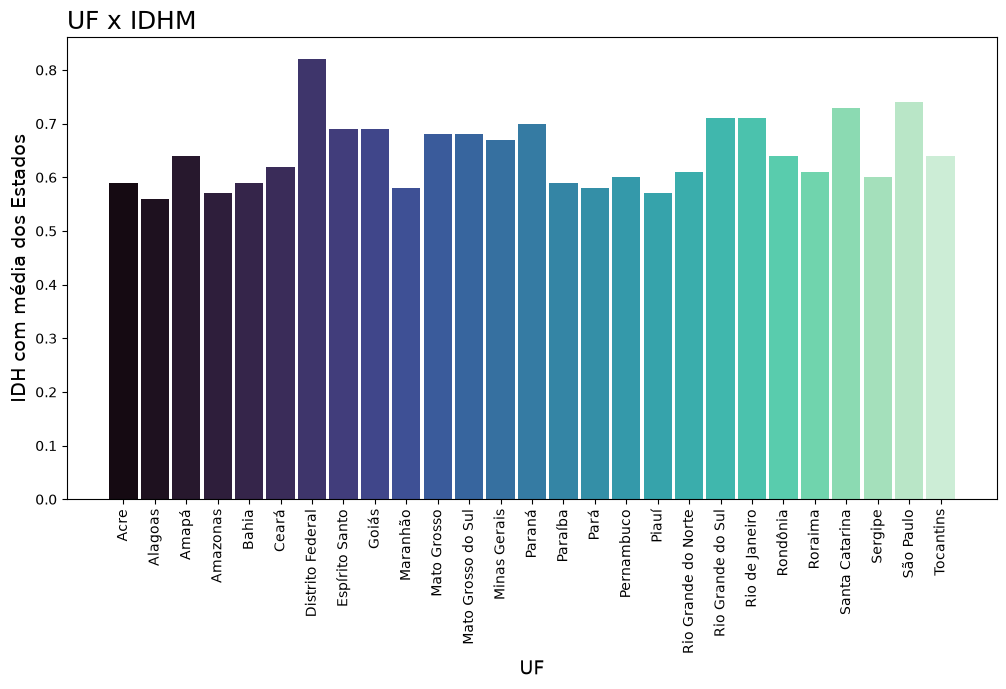

In [30]:
# Tamanho da figura
plt.figure(figsize=(12, 6))

# Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))

# Gráfico de Barras
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm'],
        width=0.9,
        color=Paleta_Cores)

# Título
plt.title('UF x IDHM', loc = 'left', fontsize=18)

# Labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDH com média dos Estados', fontsize = 14)
plt.xticks(rotation = 90);

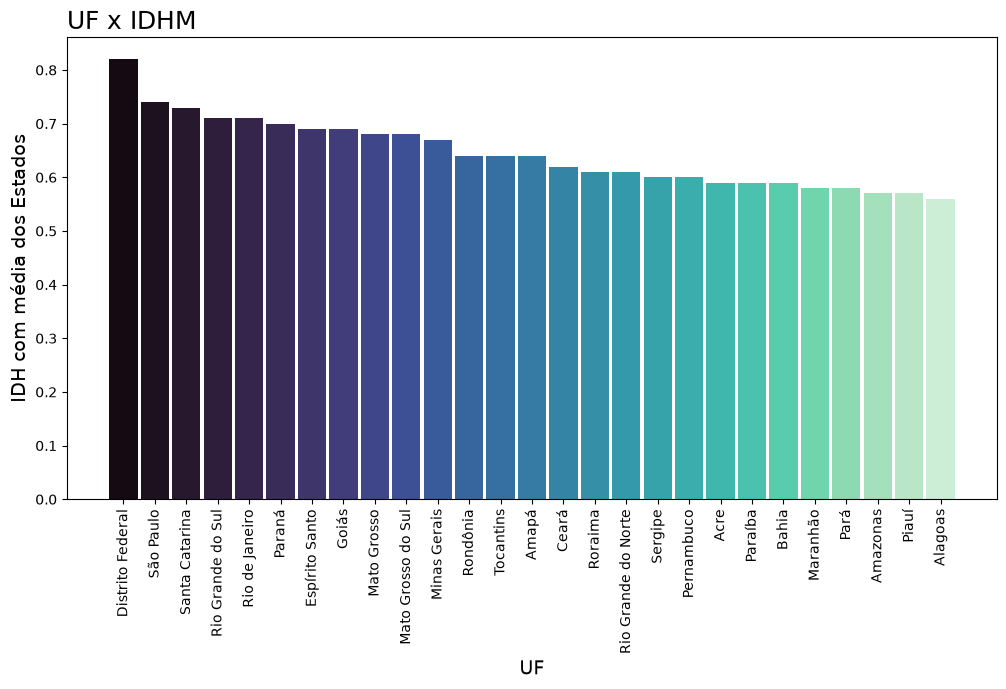

In [31]:
df_idhm_estado = df_idhm_estado.sort_values(by='idhm', ascending=False)

# Tamanho da figura
plt.figure(figsize=(12, 6))

# Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))

# Gráfico de Barras
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm'],
        width=0.9,
        color=Paleta_Cores)

# Título
plt.title('UF x IDHM', loc = 'left', fontsize=18)

# Labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDH com média dos Estados', fontsize = 14)
plt.xticks(rotation = 90);

In [32]:
df_idhm_estado.head(10)

,uf,idhm,classe
6,Distrito Federal,0.82,Alto Desenvolvimento Humano
25,São Paulo,0.74,Médio Desenvolvimento Humano
23,Santa Catarina,0.73,Médio Desenvolvimento Humano
19,Rio Grande do Sul,0.71,Médio Desenvolvimento Humano
20,Rio de Janeiro,0.71,Médio Desenvolvimento Humano
13,Paraná,0.70,Médio Desenvolvimento Humano
7,Espírito Santo,0.69,Médio Desenvolvimento Humano
8,Goiás,0.69,Médio Desenvolvimento Humano
10,Mato Grosso,0.68,Médio Desenvolvimento Humano
11,Mato Grosso do Sul,0.68,Médio Desenvolvimento Humano


In [33]:
# Criar um gráfico de barras usando o Plotly
fig = px.bar(df_idhm_estado,
             x='uf',
             y='idhm',
             color='classe',
             title='IDHM por Estado',
             color_discrete_sequence=['green','orange']
             )
fig.show()

In [ ]:
# Filtro
df_idhm_estado = pd.DataFrame(
    df_idhm.groupby('uf')[
        ['idhm', 'idhm_educacao', 'idhm_longevidade', 'idhm_renda']].mean().round(2)).reset_index()
df_idhm_estado

,uf,idhm,idhm_educacao,idhm_longevidade,idhm_renda
0,Acre,0.59,0.45,0.77,0.59
1,Alagoas,0.56,0.44,0.74,0.55
2,Amapá,0.64,0.55,0.78,0.62
3,Amazonas,0.57,0.44,0.77,0.55
4,Bahia,0.59,0.48,0.76,0.57
5,Ceará,0.62,0.55,0.76,0.56
6,Distrito Federal,0.82,0.74,0.87,0.86
7,Espírito Santo,0.69,0.59,0.83,0.68
8,Goiás,0.69,0.60,0.83,0.68
9,Maranhão,0.58,0.49,0.74,0.53


In [58]:
df_idhm_estado['classe'] = df_idhm_estado.apply(idhm_class, axis=1)
df_idhm_estado

,uf,idhm,idhm_educacao,idhm_longevidade,idhm_renda,classe
0,Acre,0.59,0.45,0.77,0.59,Médio Desenvolvimento Humano
1,Alagoas,0.56,0.44,0.74,0.55,Médio Desenvolvimento Humano
2,Amapá,0.64,0.55,0.78,0.62,Médio Desenvolvimento Humano
3,Amazonas,0.57,0.44,0.77,0.55,Médio Desenvolvimento Humano
4,Bahia,0.59,0.48,0.76,0.57,Médio Desenvolvimento Humano
5,Ceará,0.62,0.55,0.76,0.56,Médio Desenvolvimento Humano
6,Distrito Federal,0.82,0.74,0.87,0.86,Alto Desenvolvimento Humano
7,Espírito Santo,0.69,0.59,0.83,0.68,Médio Desenvolvimento Humano
8,Goiás,0.69,0.60,0.83,0.68,Médio Desenvolvimento Humano
9,Maranhão,0.58,0.49,0.74,0.53,Médio Desenvolvimento Humano


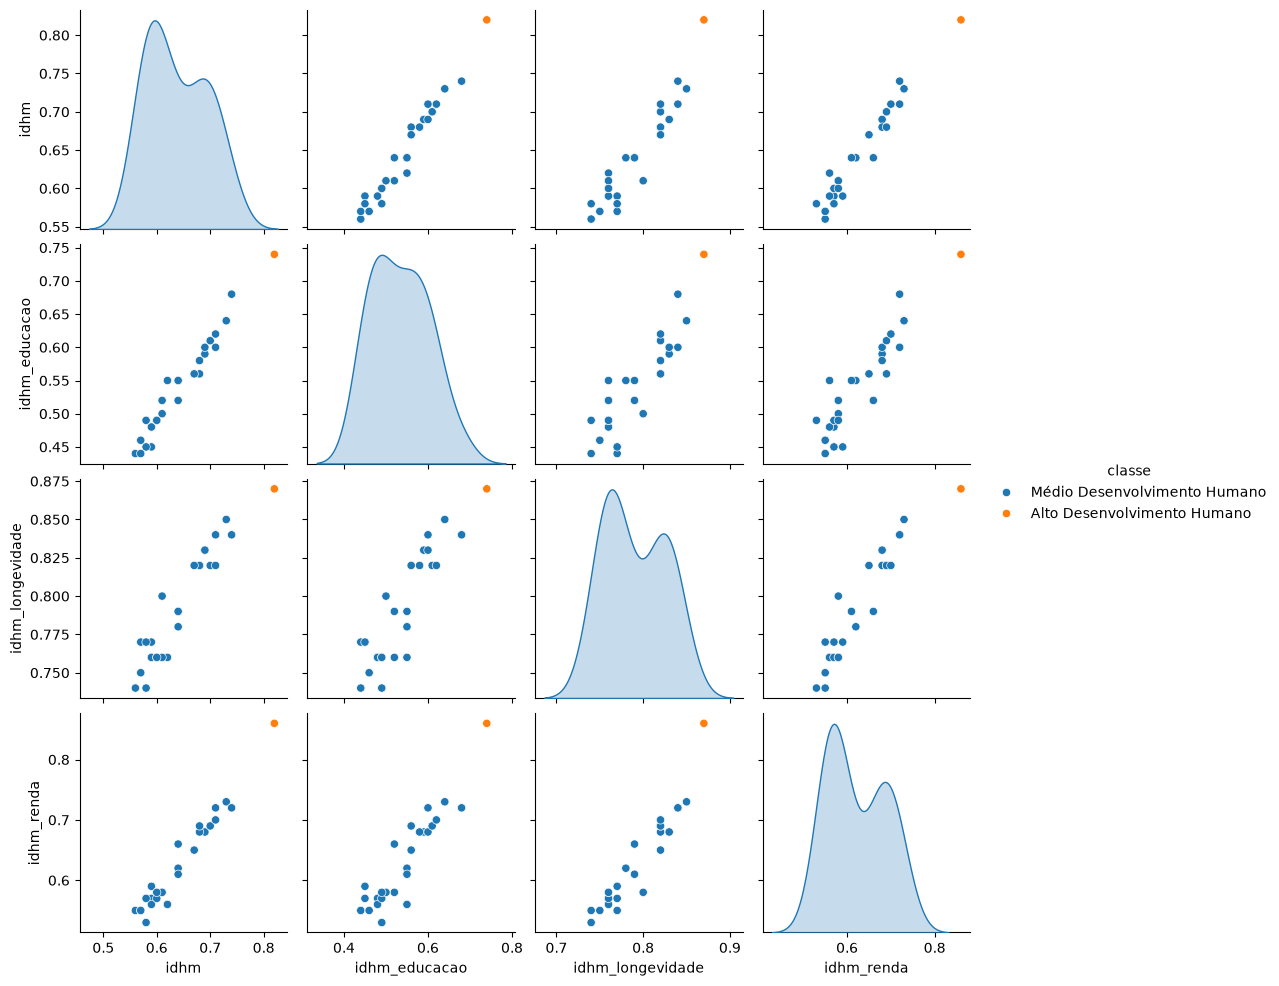

In [59]:
sns.pairplot(df_idhm_estado, hue = 'classe')

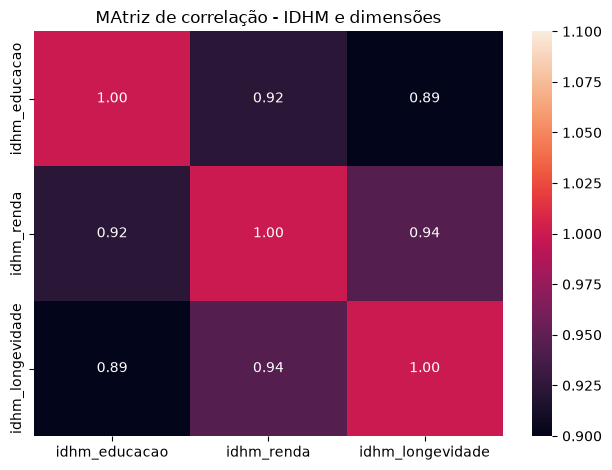

In [60]:
# Heatmap
cols_corr = [c for c in ["idhm_educacao", "idhm_renda", "idhm_longevidade"] if c in df_idhm.columns]
corr = df_idhm_estado[cols_corr].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket", vmin=1, vmax=1)
plt.title("MAtriz de correlação - IDHM e dimensões")
plt.tight_layout()
plt.show()

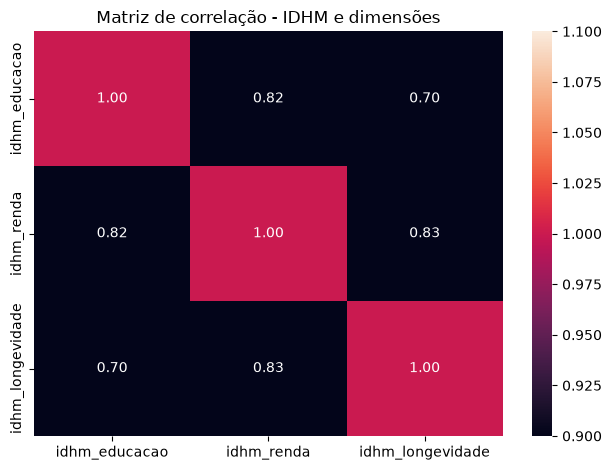

In [62]:
# Heatmap Município
cols_corr = [c for c in ["idhm_educacao", "idhm_renda", "idhm_longevidade"] if c in df_idhm.columns]
corr = df_idhm[cols_corr].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket", vmin=1, vmax=1)
plt.title("Matriz de correlação - IDHM e dimensões")
plt.tight_layout()
plt.show()

In [ ]:
#Estado
df_idhm_estado.describe().round(2)

,idhm,idhm_educacao,idhm_longevidade,idhm_renda
count,27.00,27.00,27.00,27.00
mean,0.64,0.54,0.79,0.63
std,0.06,0.08,0.04,0.08
min,0.56,0.44,0.74,0.53
25%,0.59,0.48,0.76,0.57
50%,0.64,0.55,0.79,0.61
75%,0.69,0.60,0.82,0.68
max,0.82,0.74,0.87,0.86


In [ ]:
#Município
df_idhm.describe().round(2)

,idhm,idhm_educacao,idhm_longevidade,idhm_renda
count,5564.00,5564.00,5564.00,5564.00
mean,0.66,0.56,0.80,0.64
std,0.07,0.09,0.04,0.08
min,0.42,0.21,0.67,0.40
25%,0.60,0.49,0.77,0.57
50%,0.66,0.56,0.81,0.65
75%,0.72,0.63,0.84,0.71
max,0.86,0.82,0.89,0.89


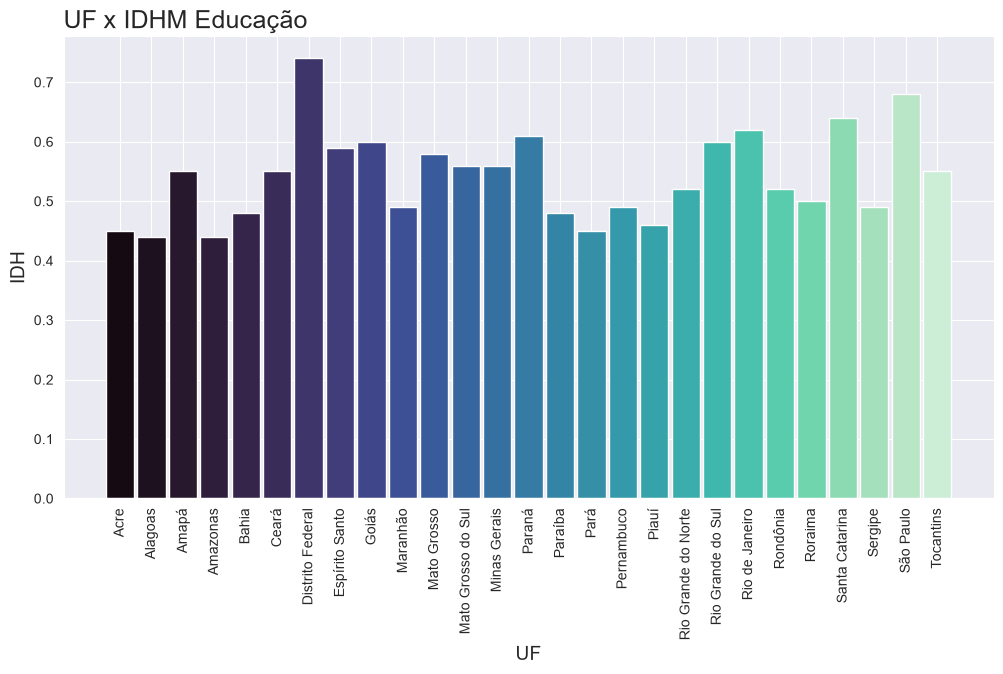

In [71]:
#Tamanho da Figura
plt.figure(figsize=(12, 6))

#Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))
sns.set_style('darkgrid')

#Plotagem
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm_educacao'],
        width=0.9,
        color=Paleta_Cores)

#Título
plt.title('UF x IDHM Educação', loc = 'left', fontsize=18)

#Labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDH', fontsize = 14)
plt.xticks(rotation = 90);

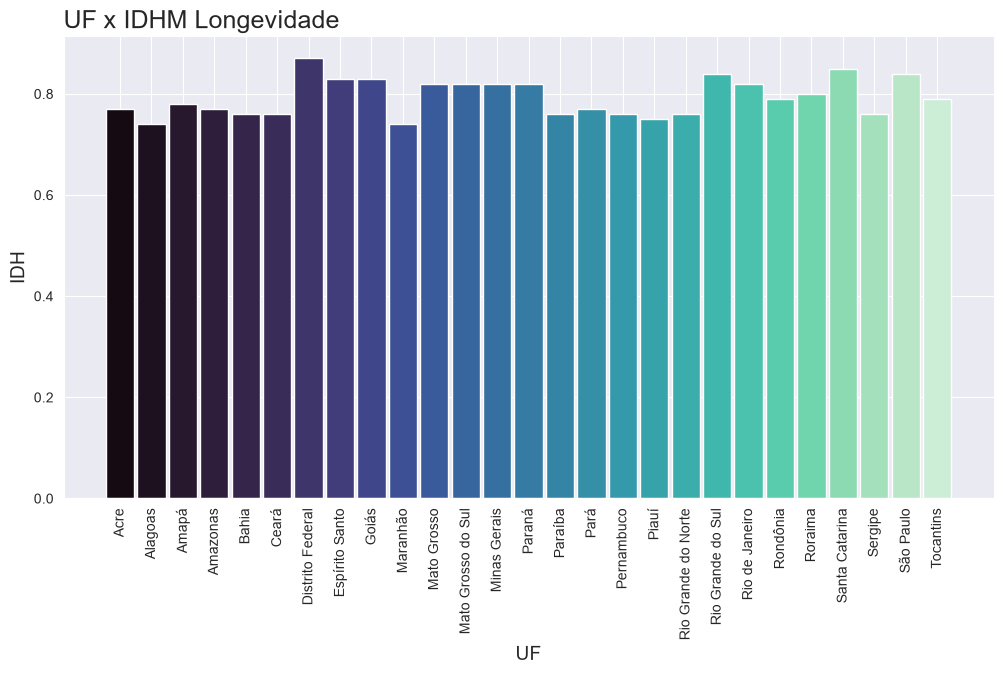

In [70]:
#Tamanho da Figura
plt.figure(figsize=(12, 6))

#Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))
sns.set_style('darkgrid')

#Plotagem
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm_longevidade'],
        width=0.9,
        color=Paleta_Cores)

#Título
plt.title('UF x IDHM Longevidade', loc = 'left', fontsize=18)

#Labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDH', fontsize = 14)
plt.xticks(rotation = 90);

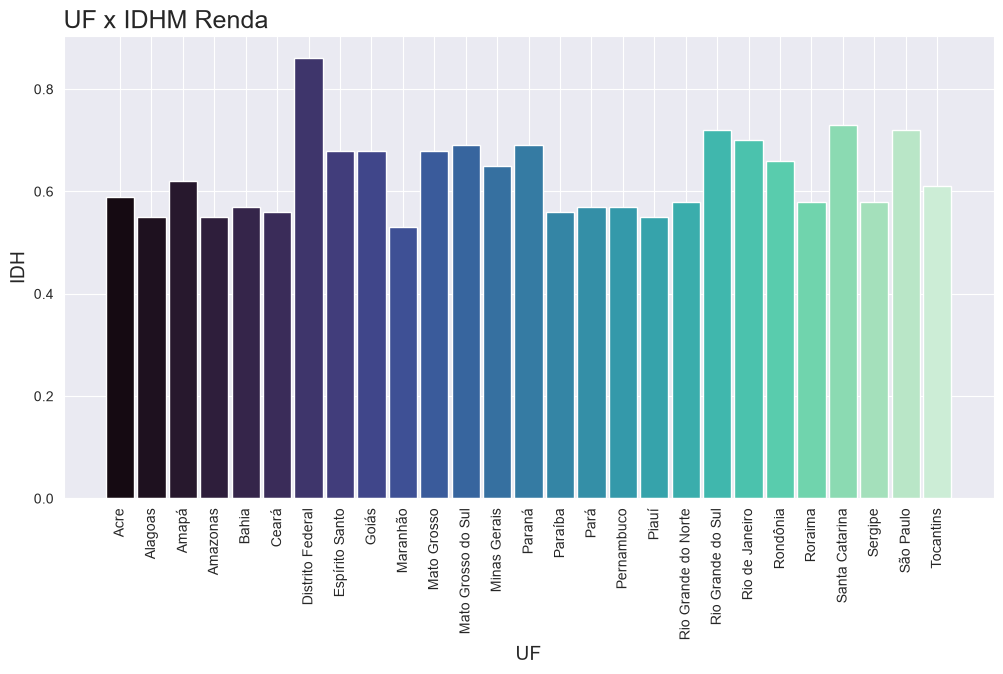

In [69]:
#Tamanho da Figura
plt.figure(figsize=(12, 6))

#Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))
sns.set_style('darkgrid')

#Plotagem
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm_renda'],
        width=0.9,
        color=Paleta_Cores)

#Título
plt.title('UF x IDHM Renda', loc = 'left', fontsize=18)

#Labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDH', fontsize = 14)
plt.xticks(rotation = 90);

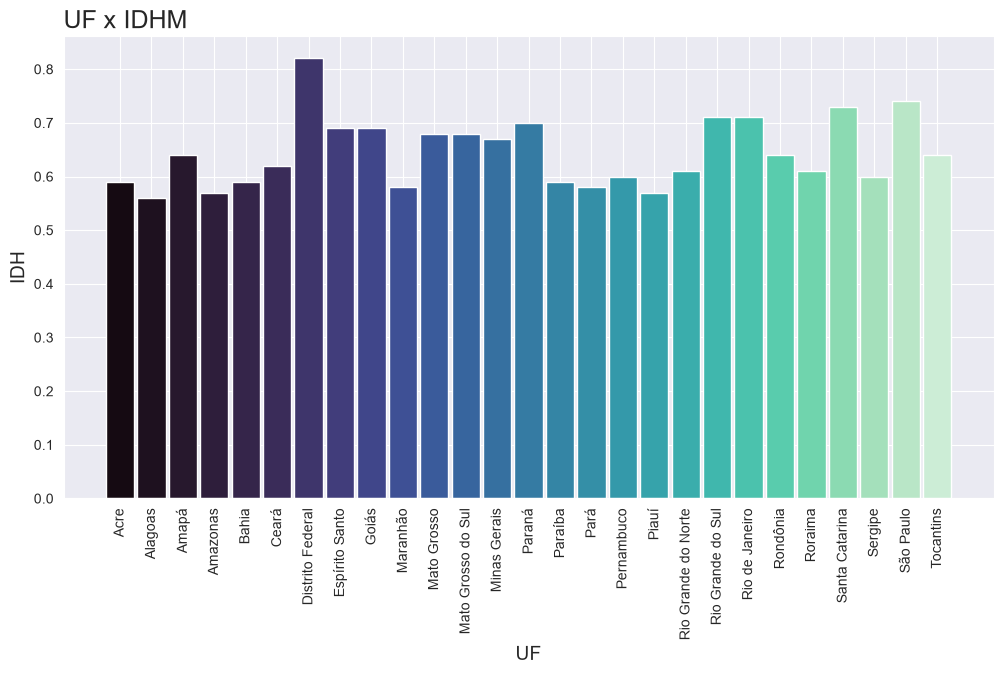

In [68]:
#Tamanho da Figura
plt.figure(figsize=(12, 6))

#Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))
sns.set_style('darkgrid')

#Plotagem
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm'],
        width=0.9,
        color=Paleta_Cores)

#Título
plt.title('UF x IDHM', loc = 'left', fontsize=18)

#Labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDH', fontsize = 14)
plt.xticks(rotation = 90);

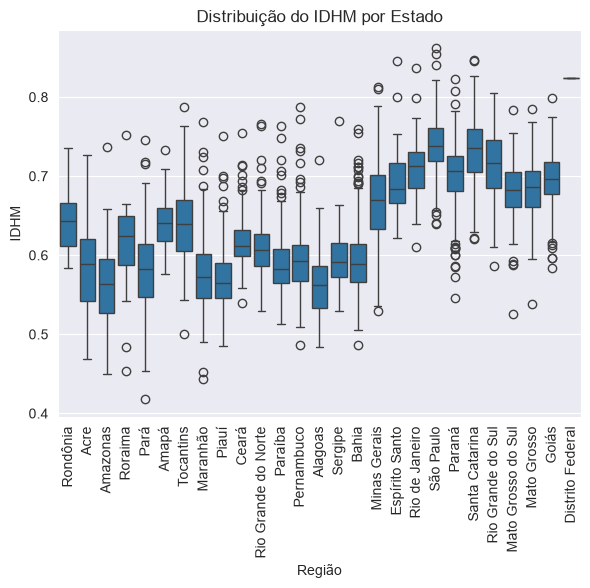

In [72]:
#Boxsplot por Estado
plt.figure()
sns.boxplot(data = df_idhm, x='uf', y='idhm') #município
plt.title('Distribuição do IDHM por Estado')
plt.xlabel('Região')
plt.ylabel('IDHM')
plt.tight_layout()
plt.xticks(rotation = 90);
plt.show()

In [ ]:
# Mapeando nome do estado -> região

mapa_regiao_nome = {
    'Acre': 'Norte',
    'Amazonas': 'Norte',
    'Roraima': 'Norte',
    'Pará': 'Norte',
    'Amapá': 'Norte',
    'Tocantins': 'Norte',
    'Rondônia': 'Norte',

    'Bahia': 'Nordeste',
    'Pernambuco': 'Nordeste',
    'Ceará': 'Nordeste',
    'Rio Grande do Norte': 'Nordeste',
    'Paraíba': 'Nordeste',
    'Piauí': 'Nordeste',
    'Maranhão': 'Nordeste',
    'Alagoas': 'Nordeste',
    'Sergipe': 'Nordeste',

    'Goiás': 'Centro-Oeste',
    'Mato Grosso': 'Centro-Oeste',
    'Mato Grosso do Sul': 'Centro-Oeste',
    'Distrito Federal': 'Centro-Oeste',

    'São Paulo': 'Sudeste',
    'Rio de Janeiro': 'Sudeste',
    'Minas Gerais': 'Sudeste',
    'Espírito Santo': 'Sudeste',

    'Paraná': 'Sul',
    'Santa Catarina': 'Sul',
    'Rio Grande do Sul': 'Sul',
}

df_idhm['regiao'] = df_idhm['uf'].map(mapa_regiao_nome) #município

df_idhm[['uf', 'regiao']].drop_duplicates().sort_values('regiao')

,uf,regiao
5563,Distrito Federal,Centro-Oeste
5176,Mato Grosso,Centro-Oeste
5098,Mato Grosso do Sul,Centro-Oeste
5317,Goiás,Centro-Oeste
1825,Bahia,Nordeste
1750,Sergipe,Nordeste
1463,Pernambuco,Nordeste
1240,Paraíba,Nordeste
1073,Rio Grande do Norte,Nordeste
1648,Alagoas,Nordeste


In [74]:
df_idhm.head()

,uf,municipio,idhm,idhm_educacao,idhm_longevidade,idhm_renda,classe,regiao
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657,Médio Desenvolvimento Humano,Norte
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716,Médio Desenvolvimento Humano,Norte
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650,Médio Desenvolvimento Humano,Norte
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727,Médio Desenvolvimento Humano,Norte
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688,Médio Desenvolvimento Humano,Norte


In [79]:
idhm_regiao = df_idhm.groupby('regiao')['idhm'].mean().sort_values()

In [80]:
idhm_regiao

regiao
Nordeste        0.590672
Norte           0.607951
Centro-Oeste    0.689468
Sudeste         0.698984
Sul             0.714113
Name: idhm, dtype: float64

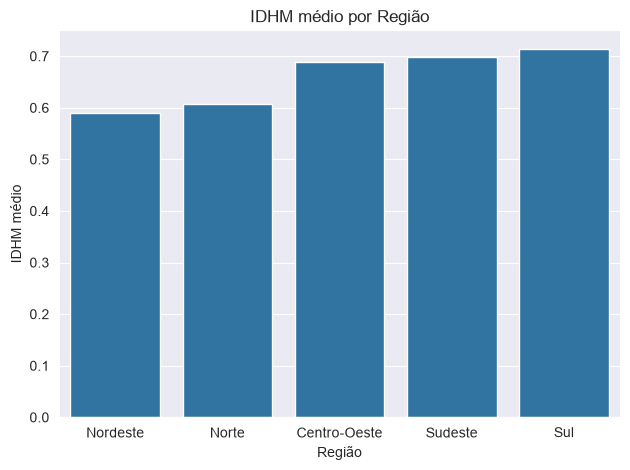

In [81]:
plt.figure()
sns.barplot(x=idhm_regiao.index, y=idhm_regiao.values)
plt.title('IDHM médio por Região')
plt.xlabel('Região')
plt.ylabel('IDHM médio')
plt.tight_layout()
plt.show()

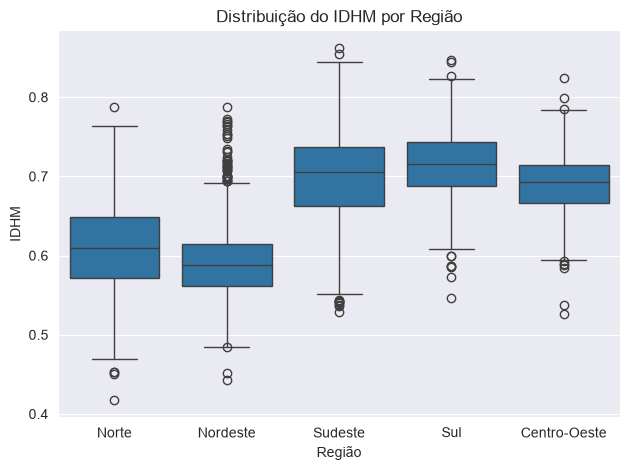

In [82]:
plt.figure()
sns.boxplot(data = df_idhm, x='regiao', y='idhm') #município
plt.title('Distribuição do IDHM por Região')
plt.xlabel('Região')
plt.ylabel('IDHM')
plt.tight_layout()
plt.show()

In [85]:
N = 10

if "municipio" in df_idhm.columns:
    maiores = df_idhm.sort_values("idhm", ascending=False).head(N)[["municipio", "uf", "idhm", "regiao"]].copy()
    menores = df_idhm.sort_values("idhm", ascending=True).head(N)[["municipio", "uf", "idhm", "regiao"]].copy()
else:
    maiores = df_idhm.sort_values("idhm", ascending=False).head(N)[["uf", "idhm"]].copy()
    menores = df_idhm.sort_values("idhm", ascending=True).head(N)[["uf", "idhm"]].copy()

#Criar coluna indicando se é Maiores ou Menores
maiores["tipo"] = "Maiores"
menores["tipo"] = "Menores"

#Unir tudo em um único dataframe
ranking_idhm = pd.concat([maiores, menores], axis=0).reset_index(drop=True)

ranking_idhm

,municipio,uf,idhm,regiao,tipo
0,SÃO CAETANO DO SUL,São Paulo,0.862,Sudeste,Maiores
1,ÁGUAS DE SÃO PEDRO,São Paulo,0.854,Sudeste,Maiores
2,FLORIANÓPOLIS,Santa Catarina,0.847,Sul,Maiores
3,VITÓRIA,Espírito Santo,0.845,Sudeste,Maiores
4,BALNEÁRIO CAMBORIÚ,Santa Catarina,0.845,Sul,Maiores
5,SANTOS,São Paulo,0.840,Sudeste,Maiores
6,NITERÓI,Rio de Janeiro,0.837,Sudeste,Maiores
7,JOAÇABA,Santa Catarina,0.827,Sul,Maiores
8,BRASÍLIA,Distrito Federal,0.824,Centro-Oeste,Maiores
9,CURITIBA,Paraná,0.823,Sul,Maiores


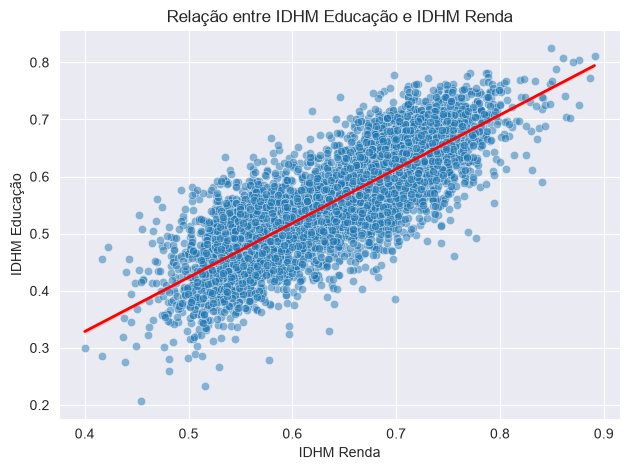

In [86]:
sns.scatterplot(data=df_idhm, x="idhm_renda", y="idhm_educacao", alpha=0.5)

# Linha de tendência com regplot
sns.regplot(
    data=df_idhm,
    x="idhm_renda",
    y="idhm_educacao",
    scatter=False,          # não recria os pontos
    color="red",            # linha de tendência em vermelho
    line_kws={"linewidth": 2}  # deixa a linha mais grossa
)

plt.title("Relação entre IDHM Educação e IDHM Renda")
plt.xlabel("IDHM Renda")
plt.ylabel("IDHM Educação")
plt.tight_layout()
plt.show()

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26],
 [Text(0, 0, 'Distrito Federal'),
  Text(1, 0, 'São Paulo'),
  Text(2, 0, 'Santa Catarina'),
  Text(3, 0, 'Rio de Janeiro'),
  Text(4, 0, 'Paraná'),
  Text(5, 0, 'Goiás'),
  Text(6, 0, 'Rio Grande do Sul'),
  Text(7, 0, 'Espírito Santo'),
  Text(8, 0, 'Mato Grosso'),
  Text(9, 0, 'Mato Grosso do Sul'),
  Text(10, 0, 'Minas Gerais'),
  Text(11, 0, 'Ceará'),
  Text(12, 0, 'Amapá'),
  Text(13, 0, 'Tocantins'),
  Text(14, 0, 'Rio Grande do Norte'),
  Text(15, 0, 'Rondônia'),
  Text(16, 0, 'Roraima'),
  Text(17, 0, 'Maranhão'),
  Text(18, 0, 'Pernambuco'),
  Text(19, 0, 'Sergipe'),
  Text(20, 0, 'Paraíba'),
  Text(21, 0, 'Bahia'),
  Text(22, 0, 'Piauí'),
  Text(23, 0, 'Acre'),
  Text(24, 0, 'Pará'),
  Text(25, 0, 'Amazonas'),
  Text(26, 0, 'Alagoas')])

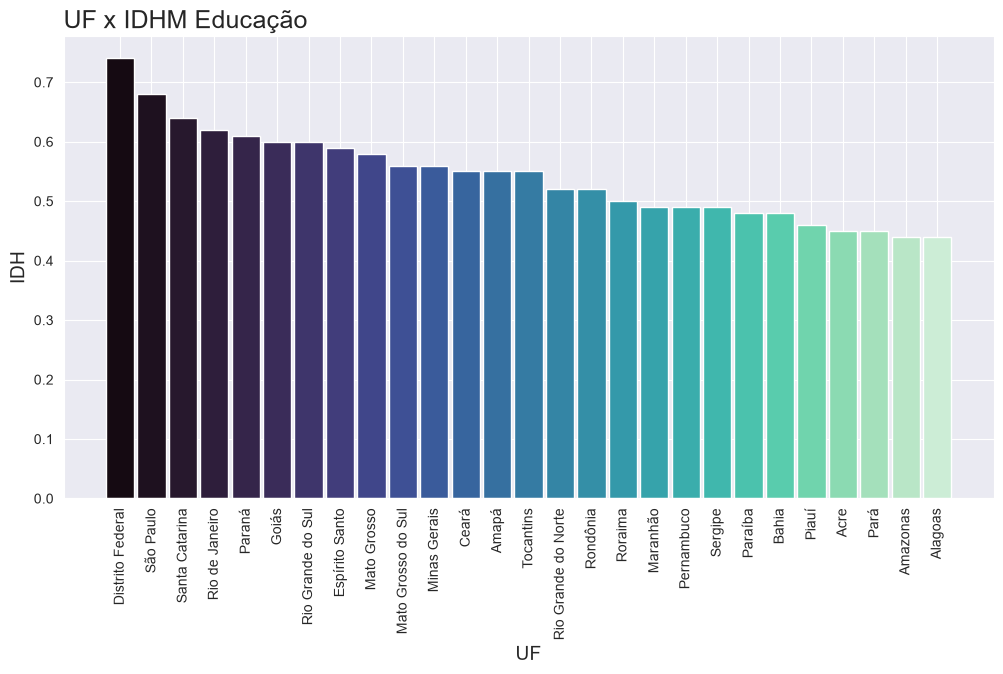

In [87]:
# Ordenar os dados do maior para o menor número de infecções
df_idhm_estado = df_idhm_estado.sort_values(by="idhm_educacao", ascending=False)

# Tamanho da Figura
plt.figure(figsize=(12,6))

# Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))
sns.set_style('darkgrid')

# Plotagem
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm_educacao'],
        width=0.9,
        color=Paleta_Cores
        )

# Título
plt.title('UF x IDHM Educação', loc='left', fontsize=18)

# Labels
plt.xlabel('UF', fontsize=14)
plt.ylabel('IDH', fontsize=14)
plt.xticks(rotation=90)

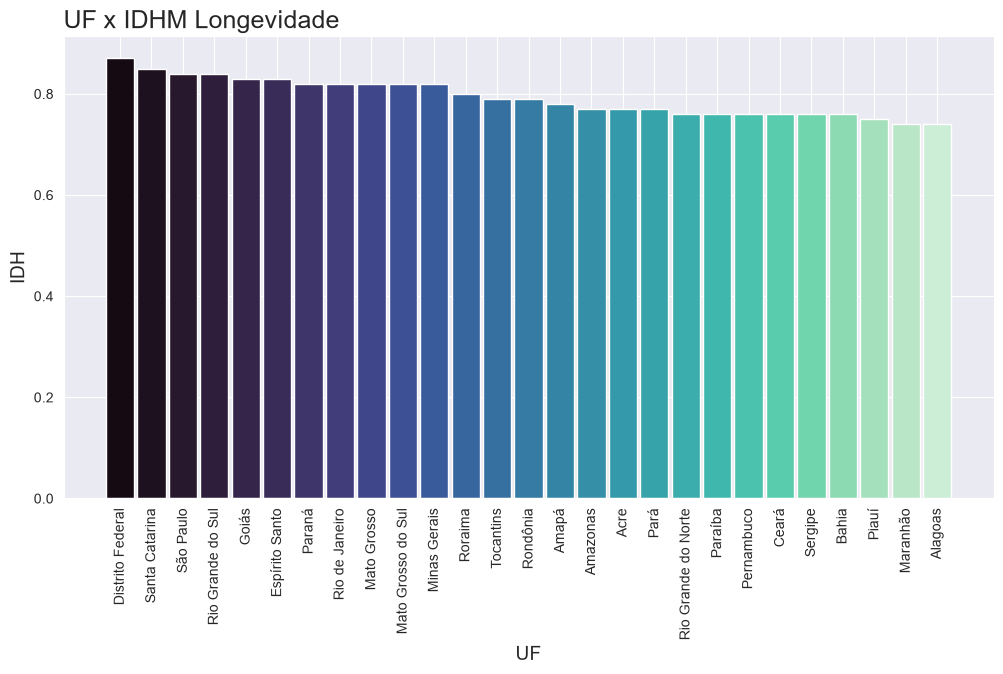

In [88]:
# Ordenar os dados do maior para o menor número de infecções
df_idhm_estado = df_idhm_estado.sort_values(by="idhm_longevidade", ascending=False)

# Tamanho da Figura
plt.figure(figsize=(12,6))

# Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))
sns.set_style('darkgrid')

# Plotagem
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm_longevidade'],
        width=0.9,
        color=Paleta_Cores
        )

# Título
plt.title('UF x IDHM Longevidade', loc='left', fontsize=18)

# Labels
plt.xlabel('UF', fontsize=14)
plt.ylabel('IDH', fontsize=14)
plt.xticks(rotation=90);

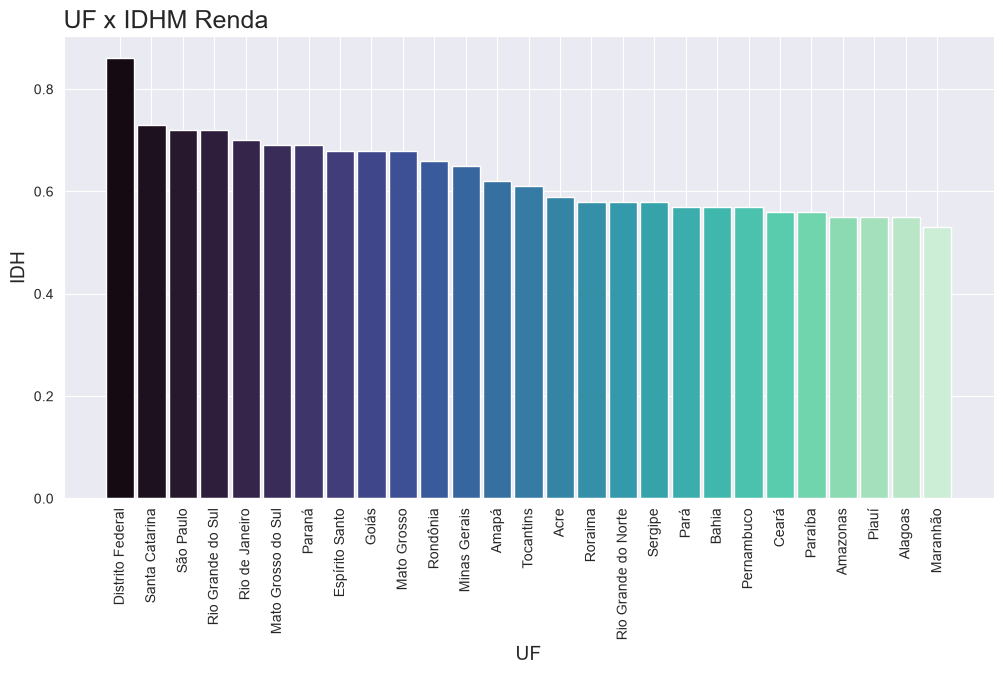

In [89]:
# Ordenar os dados do maior para o menor número de infecções
df_idhm_estado = df_idhm_estado.sort_values(by="idhm_renda", ascending=False)

# Tamanho da Figura
plt.figure(figsize=(12,6))

# Paleta de Cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))
sns.set_style('darkgrid')

# Plotagem
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm_renda'],
        width=0.9,
        color=Paleta_Cores
        )

# Título
plt.title('UF x IDHM Renda', loc='left', fontsize=18)

# Labels
plt.xlabel('UF', fontsize=14)
plt.ylabel('IDH', fontsize=14)
plt.xticks(rotation=90);

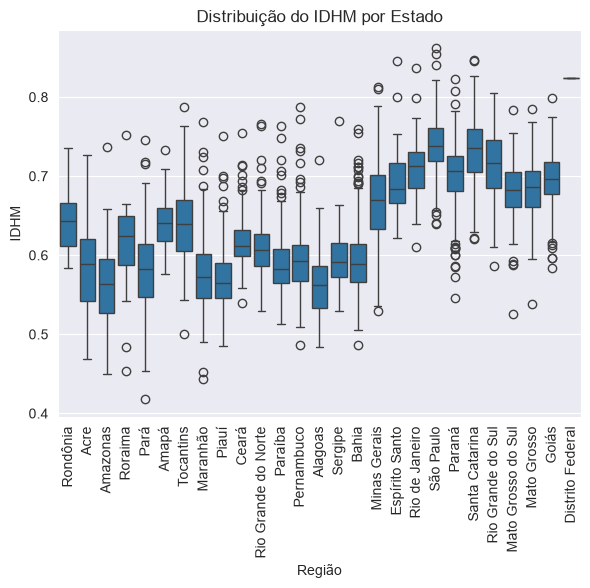

In [90]:
# Boxplot por estado
plt.figure()
sns.boxplot(data=df_idhm, x="uf", y="idhm") #municipio

plt.title("Distribuição do IDHM por Estado")
plt.xlabel("Região")
plt.ylabel("IDHM")
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()